# PaceForge — Component 1: Model Training

This notebook trains and evaluates the marathon finish-time model for recreational and
beginner runners.

**Personal best (PB) is an optional input.** A runner who has run a marathon before can
enter their PB, and the model uses it. A first-timer leaves it blank, and the model still
gives a prediction from the other inputs, so the cold-start case is kept.

**Important:** the dataset is synthetic. This notebook demonstrates the machine learning
pipeline (preprocessing, tuning, evaluation, explainability). The scores below describe
performance **on this dataset only** and are not real-world accuracy claims.

| Input | Rows |
|---|---|
| `../dataset/clean.csv` (train) | 77,577 |
| `../dataset/clean_test.csv` (test) | 19,380 |

Outputs: `../models/model.joblib`, tables in `../results/`, figures in `../figures/`.
The earlier cold-start-only version (9 inputs, no PB) is archived in
`../archive/v1_coldstart/` for comparison.

In [1]:
import os
os.environ["LOKY_MAX_CPU_COUNT"] = "4"  # silences the Windows loky "physical cores" warning

import sys
import time

import joblib
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.base import clone
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (mean_absolute_error, mean_absolute_percentage_error,
                             r2_score, root_mean_squared_error)
from sklearn.model_selection import KFold, RandomizedSearchCV, cross_val_score
from sklearn.neural_network import MLPRegressor

sys.path.insert(0, "..")
from src.pipeline import PB, build_pipeline, feature_list
from src.riegel import all_distances

RANDOM_STATE = 42

os.makedirs("../models", exist_ok=True)
os.makedirs("../results", exist_ok=True)
os.makedirs("../figures", exist_ok=True)

# Chart colours (blue = ML models, grey = baselines)
BLUE = "#2a78d6"
GREY = "#898781"
INK = "#0b0b0b"
GRID = "#e1e0d9"
plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": INK,
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
    "axes.grid": True,
    "grid.color": GRID,
    "grid.linewidth": 0.6,
    "axes.axisbelow": True,
})

## Step 1 — Load the data

Load the cleaned train and test files and check the row counts.

- Target `y` = `actual_finish_time_minutes`
- Inputs `X` (11 columns), defined once in `src/pipeline.py`:
  - 7 numeric: `age`, `bmi`, `weekly_km`, `runs_per_week`, `long_run_distance_km`,
    `resting_heart_rate_bpm`, `running_experience_months`
  - `personal_best_minutes` — **optional**. It is empty (NaN) for first-timers, and it
    stays empty in the CSV files.
  - 3 categorical: `gender`, `course_difficulty`, `injury_severity`

In [2]:
train = pd.read_csv("../dataset/clean.csv")
test = pd.read_csv("../dataset/clean_test.csv")

assert len(train) == 77_577
assert len(test) == 19_380

TARGET = "actual_finish_time_minutes"
FEATURES = feature_list()
assert len(FEATURES) == 11

X_train, y_train = train[FEATURES], train[TARGET]
X_test, y_test = test[FEATURES], test[TARGET]

print("Inputs:", FEATURES)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("PB missing (first-timers): train", X_train[PB].isna().sum(), "| test", X_test[PB].isna().sum())

Inputs: ['age', 'bmi', 'weekly_km', 'runs_per_week', 'long_run_distance_km', 'resting_heart_rate_bpm', 'running_experience_months', 'personal_best_minutes', 'gender', 'course_difficulty', 'injury_severity']
Train: (77577, 11) | Test: (19380, 11)
PB missing (first-timers): train 10415 | test 2571


## Step 2 — Train / test setup

There is **no** `train_test_split`. The dataset comes with its own independent test set:

- **Train** = all of `clean.csv`. Used for fitting and for 5-fold cross-validation (CV)
  during tuning.
- **Test** = all of `clean_test.csv`. Used **only** for the final scores. It is never
  used for tuning.

In [3]:
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
print("Training rows:", len(X_train), "| Test rows (final scores only):", len(X_test))

Training rows: 77577 | Test rows (final scores only): 19380


## Step 3 — Preprocessing (inside the Pipeline)

The preprocessing lives in `src/pipeline.py`, so notebook 03 uses exactly the same setup.
`build_pipeline(model)` returns `Pipeline([("pre", ColumnTransformer), ("model", model)])`:

| Columns | Transformer |
|---|---|
| 7 numeric columns | `StandardScaler` |
| `personal_best_minutes` | `SimpleImputer(strategy="median", add_indicator=True)`, then `StandardScaler` |
| `gender` | `OneHotEncoder(drop="first")` (Female is the reference; Male and Non-binary each get a column) |
| `course_difficulty` | `OrdinalEncoder`: Flat = 0, Mixed = 1, Hilly = 2 |
| `injury_severity` | `OrdinalEncoder`: No injury = 0, Minor = 1, Moderate = 2, Severe = 3 |

**How a missing PB is handled (the missing-indicator method).** Most models cannot work
with an empty value, so the pipeline does two things for `personal_best_minutes`:

1. It adds an extra **"PB is missing" flag** (1 for first-timers, 0 for everyone else).
   This flag tells the model which runners have no PB.
2. It fills the empty PB with a **placeholder**: the median PB of the training data. The
   placeholder is not a guess of the runner's PB; it only keeps the column usable. Because
   the flag is there, the model can learn to ignore the placeholder for first-timers.

The PB is **not** filled in the CSV files. The placeholder only exists inside the
pipeline, and the median is learned in `fit()`, so during cross-validation it comes from
the training folds only. The scaler and encoders are fit the same way, so no information
from the validation fold (or the test set) leaks into preprocessing.

`build_pipeline` also takes `use_pb`, `use_injury` and `drop` arguments, which the
ablations in Step 6 use to remove one input. Below, the pipeline is fit once to show the
13 columns the model actually receives (note the extra PB-missing flag).

In [4]:
example = build_pipeline(LinearRegression()).fit(X_train, y_train)
print(list(example.named_steps["pre"].get_feature_names_out()))
example

['num__age', 'num__bmi', 'num__weekly_km', 'num__runs_per_week', 'num__long_run_distance_km', 'num__resting_heart_rate_bpm', 'num__running_experience_months', 'pb__personal_best_minutes', 'pb__missingindicator_personal_best_minutes', 'gender__gender_Male', 'gender__gender_Non-binary', 'course__course_difficulty', 'injury__injury_severity']


Pipeline(steps=[('pre',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['age', 'bmi', 'weekly_km',
                                                   'runs_per_week',
                                                   'long_run_distance_km',
                                                   'resting_heart_rate_bpm',
                                                   'running_experience_months']),
                                                 ('pb',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer(add_indicator=True,
                                                                                 strategy='median')),
                                                                  ('scale',
                                                                   StandardScaler())]),
                                                  ['personal_best_minutes']),
                                                 ('gender',
                                                  OneHotEncoder(drop='first'),
                                                  ['gender']),
                                                 ('course',
                                                  OrdinalEncoder(categories=[['Flat',
                                                                              'Mixed',
                                                                              'Hilly']]),
                                                  ['course_difficulty']),
                                                 ('injury',
                                                  OrdinalEncoder(categories=[['No '
                                                                              'injury',
                                                                              'Minor',
                                                                              'Moderate',
                                                                              'Severe']]),
                                                  ['injury_severity'])])),
                ('model', LinearRegression())])

## Step 4 — Train and tune the 4 models

Linear regression is the baseline and has no hyperparameters to tune. The other three
models are tuned with `RandomizedSearchCV` on the **train set only**: 5-fold CV,
scoring = negative MAE, `random_state=42`, `n_jobs=-1`. The search spaces are the same as
in the cold-start version.

| Model | Class | n_iter | Search space |
|---|---|---|---|
| Linear regression (baseline) | `LinearRegression` | no tuning | – |
| Random forest | `RandomForestRegressor` | 10 | n_estimators [100, 200]; max_depth [None, 10, 20]; min_samples_leaf [1, 5, 10]; max_features ["sqrt", 0.5, 1.0] |
| Gradient boosting | `HistGradientBoostingRegressor` | 20 | learning_rate [0.03, 0.05, 0.1]; max_iter [200, 400, 800]; max_depth [None, 4, 8]; min_samples_leaf [20, 50, 100]; l2_regularization [0, 0.1, 1.0] |
| Neural network | `MLPRegressor(early_stopping=True, max_iter=500)` | 20 | hidden_layer_sizes [(32,), (64, 32), (128, 64)]; alpha [1e-4, 1e-3, 1e-2]; learning_rate_init [1e-3, 1e-2] |

Note: the neural network search space has only 3 × 3 × 2 = 18 combinations, fewer than
`n_iter=20`. scikit-learn then tries all 18 (it cannot sample more combinations than
exist), so for this model the search is effectively a full grid search.

After the search, `RandomizedSearchCV` refits the best settings on the full train set.
The best settings and their CV MAE are saved to `results/best_params.csv`.

In [5]:
SEARCHES = {
    "Random forest": (
        RandomForestRegressor(random_state=RANDOM_STATE),
        {
            "model__n_estimators": [100, 200],
            "model__max_depth": [None, 10, 20],
            "model__min_samples_leaf": [1, 5, 10],
            "model__max_features": ["sqrt", 0.5, 1.0],
        },
        10,
    ),
    "Gradient boosting": (
        HistGradientBoostingRegressor(random_state=RANDOM_STATE),
        {
            "model__learning_rate": [0.03, 0.05, 0.1],
            "model__max_iter": [200, 400, 800],
            "model__max_depth": [None, 4, 8],
            "model__min_samples_leaf": [20, 50, 100],
            "model__l2_regularization": [0, 0.1, 1.0],
        },
        20,
    ),
    "Neural network": (
        MLPRegressor(early_stopping=True, max_iter=500, random_state=RANDOM_STATE),
        {
            "model__hidden_layer_sizes": [(32,), (64, 32), (128, 64)],
            "model__alpha": [1e-4, 1e-3, 1e-2],
            "model__learning_rate_init": [1e-3, 1e-2],
        },
        20,
    ),
}

tuned = {}
param_rows = []

# Linear regression: no tuning, but report its CV MAE for comparison
lr_pipeline = build_pipeline(LinearRegression())
lr_cv_mae = -cross_val_score(lr_pipeline, X_train, y_train, cv=cv,
                             scoring="neg_mean_absolute_error", n_jobs=-1).mean()
tuned["Linear regression"] = lr_pipeline.fit(X_train, y_train)
param_rows.append({"Model": "Linear regression", "Best params": "no tuning",
                   "CV MAE": round(lr_cv_mae, 2)})
print(f"Linear regression: CV MAE = {lr_cv_mae:.2f}")

for name, (model, space, n_iter) in SEARCHES.items():
    start = time.time()
    search = RandomizedSearchCV(
        build_pipeline(model),
        space,
        n_iter=n_iter,
        cv=cv,
        scoring="neg_mean_absolute_error",
        random_state=RANDOM_STATE,
        n_jobs=-1,
    )
    search.fit(X_train, y_train)
    tuned[name] = search.best_estimator_

    best = {k.replace("model__", ""): v for k, v in search.best_params_.items()}
    param_rows.append({"Model": name, "Best params": str(best),
                       "CV MAE": round(-search.best_score_, 2)})
    print(f"{name}: CV MAE = {-search.best_score_:.2f} | {best} "
          f"| {time.time() - start:.0f} s")

best_params = pd.DataFrame(param_rows)
best_params.to_csv("../results/best_params.csv", index=False)
best_params

Linear regression: CV MAE = 12.36


Random forest: CV MAE = 11.30 | {'n_estimators': 100, 'min_samples_leaf': 5, 'max_features': 0.5, 'max_depth': 20} | 433 s


Gradient boosting: CV MAE = 11.13 | {'min_samples_leaf': 50, 'max_iter': 800, 'max_depth': 4, 'learning_rate': 0.1, 'l2_regularization': 1.0} | 84 s


C:\Users\Ahmad Naji\anaconda3\Lib\site-packages\sklearn\model_selection\_search.py:320: UserWarning: The total space of parameters 18 is smaller than n_iter=20. Running 18 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(


Neural network: CV MAE = 11.46 | {'learning_rate_init': 0.001, 'hidden_layer_sizes': (64, 32), 'alpha': 0.0001} | 434 s


,Model,Best params,CV MAE
0,Linear regression,no tuning,12.36
1,Random forest,"{'n_estimators': 100, 'min_samples_leaf': 5, '...",11.30
2,Gradient boosting,"{'min_samples_leaf': 50, 'max_iter': 800, 'max...",11.13
3,Neural network,"{'learning_rate_init': 0.001, 'hidden_layer_si...",11.46


## Step 5 — Evaluate on the test set

`evaluate` returns four metrics. MAE and RMSE are in minutes, MAPE is in %, and R² has
no unit.

**Table 1** scores all 4 tuned models on the full test set, plus a mean predictor
(`DummyRegressor`, which always predicts the training-set mean finish time). Any useful
model must beat the mean predictor.

**Table 2** splits the test set into two groups:

- **Has PB:** runners with a previous marathon time. The models use the PB here. We also
  score the **Riegel baseline**. Riegel's formula converts a time at one distance into a
  time at another. From marathon to marathon the distance ratio is 1, so the Riegel
  prediction is simply the runner's personal best.
- **First-timer:** runners with no previous marathon. The models run without a PB (the
  PB-missing flag is 1). Riegel cannot be applied ("N/A (no prior race)"). This is the
  cold-start case.

The best model is the one with the lowest MAE on the full test set.

In [6]:
def evaluate(y_true, y_pred):
    return {
        "MAE": round(mean_absolute_error(y_true, y_pred), 1),
        "RMSE": round(root_mean_squared_error(y_true, y_pred), 1),
        "MAPE (%)": round(mean_absolute_percentage_error(y_true, y_pred) * 100, 1),
        "R2": round(r2_score(y_true, y_pred), 3),
    }


# Table 1: full test set
mean_predictor = DummyRegressor(strategy="mean").fit(X_train, y_train)

rows = []
for name, pipeline in tuned.items():
    rows.append({"Model": name, **evaluate(y_test, pipeline.predict(X_test))})
rows.append({"Model": "Mean predictor", **evaluate(y_test, mean_predictor.predict(X_test))})

table1 = pd.DataFrame(rows)
table1.to_csv("../results/table1_test_overall.csv", index=False)
table1

,Model,MAE,RMSE,MAPE (%),R2
0,Linear regression,12.4,16.2,4.4,0.770
1,Random forest,11.3,14.4,4.0,0.816
2,Gradient boosting,11.1,14.2,3.9,0.822
3,Neural network,11.5,14.7,4.0,0.811
4,Mean predictor,27.4,33.7,9.9,-0.000


In [7]:
# Table 2: by group within the test set
has_pb = test[PB].notna()
groups = {"Has PB": has_pb, "First-timer": ~has_pb}
print("Has PB:", has_pb.sum(), "runners | First-timer:", (~has_pb).sum(), "runners")
assert has_pb.sum() == 16_809
assert (~has_pb).sum() == 2_571

rows = []
for group, mask in groups.items():
    for name, pipeline in tuned.items():
        y_pred = pipeline.predict(X_test[mask])
        rows.append({"Group": group, "n": mask.sum(), "Model": name,
                     **evaluate(y_test[mask], y_pred)})

    if group == "Has PB":
        riegel_pred = test.loc[mask, PB]
        rows.append({"Group": group, "n": mask.sum(), "Model": "Riegel baseline",
                     **evaluate(y_test[mask], riegel_pred)})
    else:
        rows.append({"Group": group, "n": mask.sum(), "Model": "Riegel baseline",
                     "MAE": "N/A (no prior race)", "RMSE": "N/A", "MAPE (%)": "N/A", "R2": "N/A"})

table2 = pd.DataFrame(rows)
table2.to_csv("../results/table2_test_by_group.csv", index=False)
table2

Has PB: 16809 runners | First-timer: 2571 runners


,Group,n,Model,MAE,RMSE,MAPE (%),R2
0,Has PB,16809,Linear regression,11.1,14.0,3.9,0.828
1,Has PB,16809,Random forest,10.5,13.2,3.7,0.846
2,Has PB,16809,Gradient boosting,10.3,13.0,3.6,0.851
3,Has PB,16809,Neural network,10.6,13.3,3.7,0.844
4,Has PB,16809,Riegel baseline,29.6,33.9,10.2,-0.019
5,First-timer,2571,Linear regression,21.1,26.4,7.6,0.403
6,First-timer,2571,Random forest,16.7,20.9,5.9,0.627
7,First-timer,2571,Gradient boosting,16.3,20.5,5.8,0.64
8,First-timer,2571,Neural network,17.2,21.6,6.1,0.6
9,First-timer,2571,Riegel baseline,N/A (no prior race),N/A,N/A,N/A


**Reading the Riegel result.** On this dataset the ML models have a lower MAE than the
Riegel baseline in the has-PB group. This is a result **on this dataset only**, and the
synthetic data puts Riegel at a disadvantage: most runners finished **slower** than their
personal best (computed below). A baseline that predicts "you will run your PB" is
therefore biased towards times that are too fast.

In [8]:
slower = test[TARGET] > test[PB]  # False when there is no PB

pct_of_has_pb = slower[has_pb].mean() * 100
pct_of_all = slower.mean() * 100
print(f"Finished slower than their PB: {pct_of_has_pb:.1f}% of has-PB runners "
      f"({pct_of_all:.1f}% of all test runners)")

Finished slower than their PB: 94.2% of has-PB runners (81.7% of all test runners)


In [9]:
# Compare UNROUNDED test MAE, because two models can tie after rounding to 1 decimal
test_mae = {name: mean_absolute_error(y_test, pipeline.predict(X_test))
            for name, pipeline in tuned.items()}
for name, mae in test_mae.items():
    print(f"{name}: test MAE = {mae:.3f}")

best_name = min(test_mae, key=test_mae.get)
best_pipeline = tuned[best_name]
print("Best model (lowest test MAE):", best_name)

Linear regression: test MAE = 12.403
Random forest: test MAE = 11.319
Gradient boosting: test MAE = 11.122
Neural network: test MAE = 11.462
Best model (lowest test MAE): Gradient boosting


## Step 6 — Ablations

Each ablation removes one input, then trains the **best model type with its tuned
settings** on the full train set and scores it on the test set with the Step 5 metrics.

- **Reference:** all 11 inputs (the Step 5 result, retrained the same way).
- **A: without PB.** Pure cold-start: no runner has a PB. Shows how much the optional PB
  adds.
- **B: without `injury_severity`.** Shows what the injury history adds.
- **C: without `running_experience_months`.** Shows how much the model depends on this
  one feature.

In [10]:
ABLATIONS = [
    ("Reference: all 11 inputs", {}),
    ("A: without PB (pure cold-start)", {"use_pb": False}),
    ("B: without injury_severity", {"use_injury": False}),
    ("C: without running_experience_months", {"drop": "running_experience_months"}),
]

rows = []
for label, options in ABLATIONS:
    columns = feature_list(**options)
    model = clone(best_pipeline.named_steps["model"])
    pipeline = build_pipeline(model, **options).fit(train[columns], y_train)
    rows.append({"Ablation": label, "Model": best_name, "Inputs": len(columns),
                 **evaluate(y_test, pipeline.predict(test[columns]))})

ablations = pd.DataFrame(rows)
ablations.to_csv("../results/ablations.csv", index=False)
ablations

,Ablation,Model,Inputs,MAE,RMSE,MAPE (%),R2
0,Reference: all 11 inputs,Gradient boosting,11,11.1,14.2,3.9,0.822
1,A: without PB (pure cold-start),Gradient boosting,10,16.4,20.6,5.8,0.625
2,B: without injury_severity,Gradient boosting,10,12.3,15.7,4.4,0.782
3,C: without running_experience_months,Gradient boosting,10,13.2,17.4,4.7,0.734


## Step 7 — Explainability and plots

**Permutation importance** shuffles one input at a time in the test set and measures how
much the MAE gets worse. A big increase means the model relies on that input. The whole
pipeline is passed in, so importance is measured on the **11 original inputs** (e.g.
`gender` as one input, not its one-hot columns, and PB as one input, not PB + flag).
Settings: `n_repeats=10`, `scoring="neg_mean_absolute_error"`, `random_state=42`.

Then the plots: actual vs predicted (plus a diagnostic version coloured by training
program), residual histogram, and MAE of all models and both baselines. All figures are
saved as 300 dpi PNGs in `../figures/`.

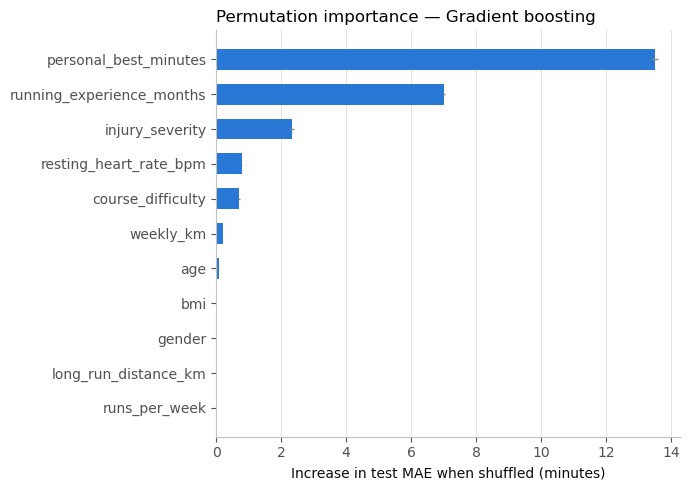

,Feature,MAE increase (min),Std
7,personal_best_minutes,13.50,0.09
6,running_experience_months,7.01,0.03
10,injury_severity,2.33,0.05
5,resting_heart_rate_bpm,0.78,0.02
9,course_difficulty,0.69,0.03
2,weekly_km,0.21,0.01
0,age,0.08,0.01
1,bmi,0.01,0.00
3,runs_per_week,0.00,0.00
4,long_run_distance_km,-0.00,0.00


In [11]:
perm = permutation_importance(
    best_pipeline, X_test, y_test,
    n_repeats=10,
    scoring="neg_mean_absolute_error",
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
importance = pd.DataFrame({
    "Feature": FEATURES,
    "MAE increase (min)": perm.importances_mean.round(2),
    "Std": perm.importances_std.round(2),
}).sort_values("MAE increase (min)", ascending=False)
importance.to_csv("../results/permutation_importance.csv", index=False)

ordered = importance.sort_values("MAE increase (min)")
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(ordered["Feature"], ordered["MAE increase (min)"], xerr=ordered["Std"],
        color=BLUE, height=0.6, error_kw={"ecolor": GREY, "lw": 1})
ax.set_xlabel("Increase in test MAE when shuffled (minutes)")
ax.set_title(f"Permutation importance — {best_name}", loc="left")
ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig("../figures/permutation_importance.png", dpi=300)
plt.show()
importance

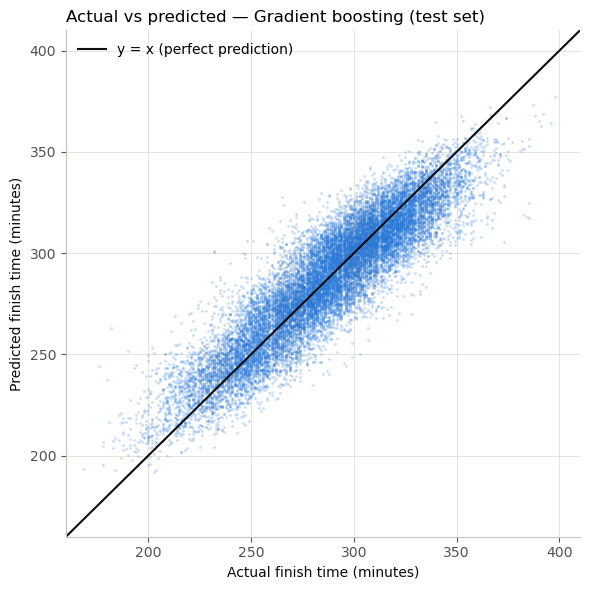

In [12]:
y_pred_best = best_pipeline.predict(X_test)

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(y_test, y_pred_best, s=4, alpha=0.25, color=BLUE, linewidths=0)
low, high = 160, 410
ax.plot([low, high], [low, high], color=INK, lw=1.5, label="y = x (perfect prediction)")
ax.set_xlim(low, high)
ax.set_ylim(low, high)
ax.set_xlabel("Actual finish time (minutes)")
ax.set_ylabel("Predicted finish time (minutes)")
ax.set_title(f"Actual vs predicted — {best_name} (test set)", loc="left")
ax.legend(loc="upper left", frameon=False)
fig.tight_layout()
fig.savefig("../figures/actual_vs_predicted.png", dpi=300)
plt.show()

### Diagnostic — training program tiers

The raw data has a `training_program` column (Beginner / Intermediate / Advanced) that was
dropped during cleaning. In this synthetic data, running experience maps **one-to-one**
onto the 3 program tiers:

| Program | Running experience |
|---|---|
| Beginner | 6–24 months |
| Intermediate | 25–60 months |
| Advanced | 61–240 months |

Each tier has its own average finish time, so once the model knows a runner's experience
it effectively knows their tier. In the cold-start version (archived in
`../archive/v1_coldstart/`) this made **all** predictions fall into 3 flat bands, one per
tier.

With the optional PB, the picture is split by group (second table below):

- **First-timers** (no PB) still get predictions close to their tier's average, so they
  still form tight bands.
- **Has-PB runners** get predictions that spread out within each tier, because the PB
  gives the model individual information about the runner.

This is a **dataset limitation, not leakage**. Running experience is a legitimate input
that a runner knows before the race, and `training_program` is **not** a model feature.
It is merged in below only to explain the plot.

In [13]:
raw_test = pd.read_csv("../dataset/test.csv", usecols=["runner_id", "training_program"])

diagnostic = test[["runner_id", "running_experience_months", PB, TARGET]].copy()
diagnostic["predicted"] = y_pred_best
diagnostic = diagnostic.merge(raw_test, on="runner_id", how="left")
assert diagnostic["training_program"].notna().all()

PROGRAMS = ["Beginner", "Intermediate", "Advanced"]
program_table = diagnostic.groupby("training_program").agg(
    Runners=("runner_id", "size"),
    Min_experience_months=("running_experience_months", "min"),
    Max_experience_months=("running_experience_months", "max"),
    Mean_actual_finish_min=(TARGET, "mean"),
).reindex(PROGRAMS).round(1)

program_table.to_csv("../results/program_diagnostic.csv")
program_table

,Runners,Min_experience_months,Max_experience_months,Mean_actual_finish_min
training_program,,,,
Beginner,9650,6,24,310.7
Intermediate,6113,25,60,278.3
Advanced,3617,61,240,244.9


In [14]:
# Spread of the predictions within each tier: first-timers vs has-PB runners
diagnostic["Group"] = diagnostic[PB].notna().map({True: "Has PB", False: "First-timer"})
spread_table = diagnostic.groupby(["Group", "training_program"]).agg(
    Runners=("runner_id", "size"),
    Mean_predicted_min=("predicted", "mean"),
    Std_predicted_min=("predicted", "std"),
).reindex(PROGRAMS, level="training_program").round(1)

spread_table.to_csv("../results/program_diagnostic_spread.csv")
spread_table

Runners  Mean_predicted_min  Std_predicted_min
Group       training_program                                                
First-timer Beginner             1269               309.7                9.0
            Intermediate          803               278.3                9.7
            Advanced              499               246.7                8.9
Has PB      Beginner             8381               310.9               18.2
            Intermediate         5310               278.0               17.8
            Advanced             3118               244.5               17.9

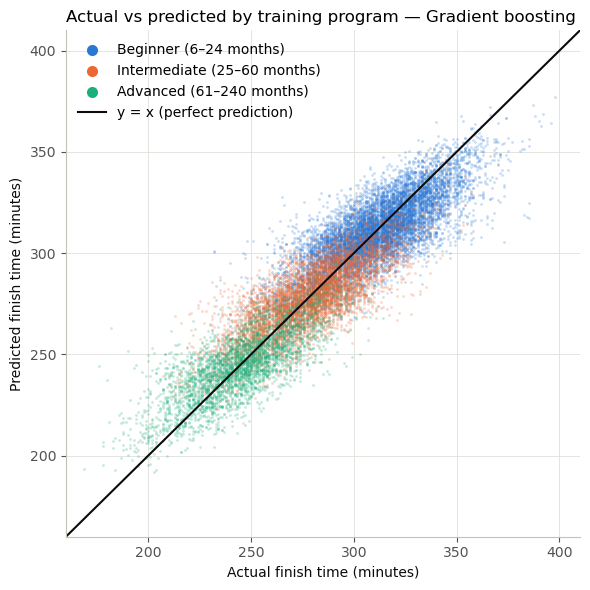

In [15]:
# Categorical colours, one fixed colour per program
PROGRAM_COLORS = {"Beginner": "#2a78d6", "Intermediate": "#eb6834", "Advanced": "#1baf7a"}

fig, ax = plt.subplots(figsize=(6, 6))
for program in PROGRAMS:
    rows = diagnostic[diagnostic["training_program"] == program]
    label = (f"{program} ({rows['running_experience_months'].min()}–"
             f"{rows['running_experience_months'].max()} months)")
    ax.scatter(rows[TARGET], rows["predicted"], s=4, alpha=0.25,
               color=PROGRAM_COLORS[program], linewidths=0, label=label)

low, high = 160, 410
ax.plot([low, high], [low, high], color=INK, lw=1.5, label="y = x (perfect prediction)")
ax.set_xlim(low, high)
ax.set_ylim(low, high)
ax.set_xlabel("Actual finish time (minutes)")
ax.set_ylabel("Predicted finish time (minutes)")
ax.set_title(f"Actual vs predicted by training program — {best_name}", loc="left")
legend = ax.legend(loc="upper left", frameon=False, markerscale=4)
for handle in legend.legend_handles:
    handle.set_alpha(1)
fig.tight_layout()
fig.savefig("../figures/actual_vs_predicted_by_program.png", dpi=300)
plt.show()

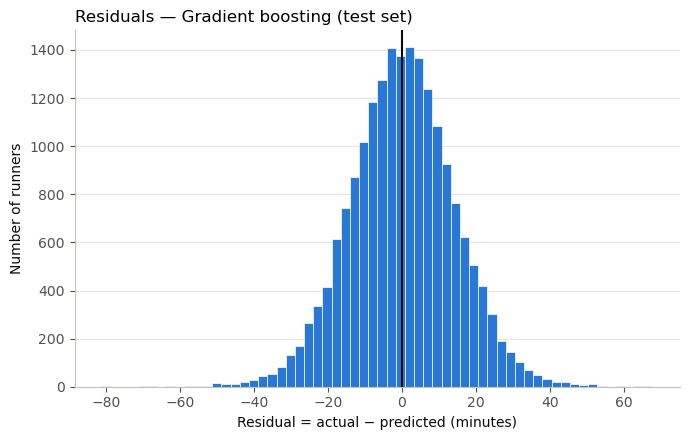

Mean residual: 0.1 min | Std: 14.2 min


In [16]:
residuals = y_test - y_pred_best  # positive = runner was slower than predicted

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.hist(residuals, bins=60, color=BLUE, edgecolor="white", linewidth=0.5)
ax.axvline(0, color=INK, lw=1.5)
ax.set_xlabel("Residual = actual − predicted (minutes)")
ax.set_ylabel("Number of runners")
ax.set_title(f"Residuals — {best_name} (test set)", loc="left")
ax.grid(axis="x", visible=False)
fig.tight_layout()
fig.savefig("../figures/residual_histogram.png", dpi=300)
plt.show()

print(f"Mean residual: {residuals.mean():.1f} min | Std: {residuals.std():.1f} min")

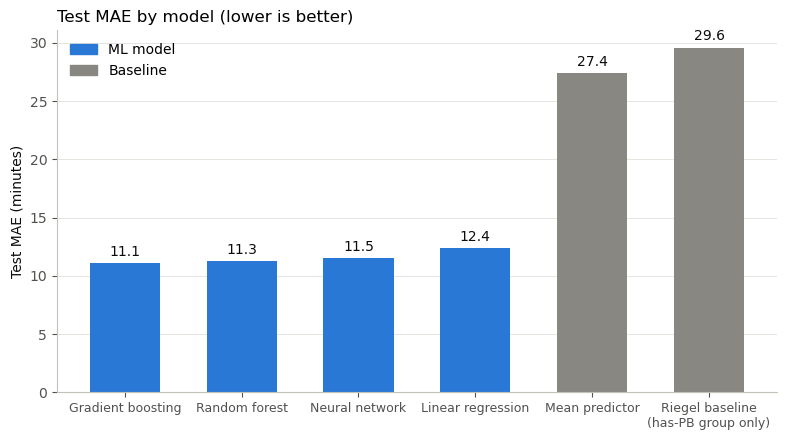

In [17]:
riegel_mae = table2.loc[(table2["Group"] == "Has PB") & (table2["Model"] == "Riegel baseline"), "MAE"].iloc[0]

mae_chart = pd.DataFrame({
    "Model": list(table1["Model"]) + ["Riegel baseline\n(has-PB group only)"],
    "MAE": list(table1["MAE"]) + [riegel_mae],
})
mae_chart["Is baseline"] = mae_chart["Model"].str.startswith(("Mean", "Riegel"))
mae_chart = mae_chart.sort_values("MAE")

fig, ax = plt.subplots(figsize=(8, 4.5))
colors = [GREY if b else BLUE for b in mae_chart["Is baseline"]]
bars = ax.bar(mae_chart["Model"], mae_chart["MAE"], color=colors, width=0.6)
ax.bar_label(bars, fmt="%.1f", padding=3, color=INK)
ax.set_ylabel("Test MAE (minutes)")
ax.set_title("Test MAE by model (lower is better)", loc="left")
ax.grid(axis="x", visible=False)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=BLUE), plt.Rectangle((0, 0), 1, 1, color=GREY)],
          labels=["ML model", "Baseline"], frameon=False, loc="upper left")
plt.setp(ax.get_xticklabels(), fontsize=9)
fig.tight_layout()
fig.savefig("../figures/mae_comparison.png", dpi=300)
plt.show()

Note: the Riegel bar is scored on the has-PB group only (16,809 runners), because
Riegel cannot be applied to first-timers. All other bars are scored on the full test
set (19,380 runners).

## Step 8 — Save the best model

The whole pipeline (preprocessing + model) is saved, so the app can pass raw inputs
straight in, with PB left empty for first-timers. To check the file works, we reload it
and confirm it gives the same prediction for one test row.

In [18]:
joblib.dump(best_pipeline, "../models/model.joblib")

reloaded = joblib.load("../models/model.joblib")
one_row = X_test.iloc[[0]]
original = best_pipeline.predict(one_row)[0]
after_reload = reloaded.predict(one_row)[0]

print(f"Saved {best_name}. Prediction before: {original:.2f} min | after reload: {after_reload:.2f} min")
assert original == after_reload

Saved Gradient boosting. Prediction before: 294.66 min | after reload: 294.66 min


## Step 9 — Riegel conversion to other distances

The model predicts a marathon time. `src/riegel.py` converts it to 5K, 10K and 21K
times with Riegel's formula, T2 = T1 × (D2 / D1)^1.06. Demo on 3 test-set predictions.

In [19]:
def to_hms(minutes):
    total_seconds = round(minutes * 60)
    hours, rest = divmod(total_seconds, 3600)
    mins, secs = divmod(rest, 60)
    return f"{hours}:{mins:02d}:{secs:02d}"


rows = []
for i in range(3):
    predicted = y_pred_best[i]
    times = all_distances(predicted)
    rows.append({"runner_id": test["runner_id"].iloc[i],
                 **{distance: to_hms(t) for distance, t in times.items()}})

riegel_demo = pd.DataFrame(rows)
riegel_demo.to_csv("../results/riegel_demo.csv", index=False)
riegel_demo

,runner_id,5K,10K,21K,42K
0,R043064,0:30:43,1:04:03,2:21:20,4:54:40
1,R030159,0:35:05,1:13:08,2:41:22,5:36:27
2,R033974,0:31:29,1:05:38,2:24:49,5:01:56
